# Milestone 1 : Cadrer et préparer les données

## 1. Spécifications fonctionnelles et hypothèses

### 1.1 Besoin
Aujourd'hui, chaque fournisseur livre chaque usine le jour exact du besoin : beaucoup de livraisons, des camions presque vides .
**Objectif** : définir pour chaque couple fournisseur × usine un **profil de livraison** (fréquence + jours) qui regroupe les besoins pour :
- réduire le nombre de livraisons,
- mieux remplir les camions sans jamais mettre l'usine en rupture,
- répartir les livraisons dans la semaine,
- chiffrer les économies.

### 1.2 Acteurs
| Acteur | Rôle |
|---|---|
| Équipe logistique | Utilise l'outil, applique les profils |
| Fournisseurs (94) | Expédient les pièces |
| Usines (4) et leurs quais | Reçoivent les pièces |
| Transporteur | Facture selon la grille tarifaire |

### 1.3 Données d'entrée
| Fichier | Contenu |
|---|---|
| `released_schedule.csv` | Besoins par jour, fournisseur, pièce, usine, quai (quantité, poids, volume) |
| `distances.csv` | Distance en km entre chaque fournisseur et le point de consolidation |
| `rate_sheet.pdf` | Coût d'un envoi selon la distance et le poids |

### 1.4 Profils de livraison
| Profil | Exemple de jours |
|---|---|
| 1 / semaine | Lundi |
| 2 / semaine | Lundi, Jeudi |
| 3 / semaine | Lundi, Mercredi, Vendredi |
| 5 / semaine | Tous les jours ouvrés |

### 1.5 Règles métier (contraintes)
| # | Règle |
|---|---|
| R1 | Une livraison peut être **avancée de 7 jours maximum**, jamais retardée |
| R2 | Capacité d'un camion : **24 500 kg** ou **110,4 m³** (la première limite atteinte) |
| R3 | Un camion = **un seul couple fournisseur × usine** |
| R4 | **Lissage** : les jours de livraison sont répartis dans la semaine sauf le weekend|
| R5 | Coût d'un envoi = coût grille × (1 + 239,23 %) × 1,1943 |

### 1.6 Hypothèses
| # | Hypothèse | Statut |
|---|---|---|
| H1 | Une ligne avec quantité = 0 n'est pas un besoin : elle est exclue | A valider |
| H2 | Distance et poids sont arrondis à la tranche **supérieure** de la grille ; < 30 km → ligne 30 km | Retenue |
| H3 | Une ligne plus lourde qu'un camion est répartie sur plusieurs camions | Retenue |
| H4 | Poids manquant → reconstitué avec le poids unitaire de la même pièce ou avec le volume | À valider |
| H5 | La colonne volume est utilisée telle quelle (elle ne varie pas avec la quantité) | À valider |
| H6 | Fournisseurs sans distance → signalés, non chiffrés | À valider |
| H7 | Pas de livraison la semaine de Noël (aucun besoin dans les données) | À valider |
| H8 | Un profil est fixe pour un couple sur toute la période | Retenue |

In [1]:
import pandas as pd

schedule = pd.read_csv("../data/released_schedule.csv", encoding="utf-8-sig")
distances = pd.read_csv("../data/distances.csv")

print("Planning :", schedule.shape)
print("Distances :", distances.shape)

Planning : (5728, 10)
Distances : (156, 2)


## 2. Analyse qualité de `released_schedule.csv`

Avant de modéliser, on vérifie la qualité du fichier `released_schedule.csv`

Rappel : capacité d'un camion = **24 500 kg** ou **110,4 m³**.
Les quantités à 0 faussent les statistiques : quand c'est utile, on calcule
chaque indicateur deux fois (sur toutes les lignes, puis sur les lignes avec
quantité > 0).

In [2]:
# Bibliotheques et constantes utilisees
import re
import numpy as np
import matplotlib.pyplot as plt

CAP_POIDS = 24500.0    # capacite camion en kg
CAP_VOLUME = 110.4     # capacite camion en m3

# Groupes de colonnes 
COLS_NUM = ["schedule_quantity", "weight", "volume"]
COLS_TEXTE = ["supplier_id", "material", "plant", "unloading_point"]
COLS_DATE = ["date", "transmission_date", "version_date"]

print("Tableau analyse :", schedule.shape[0], "lignes,", schedule.shape[1], "colonnes")

Tableau analyse : 5728 lignes, 10 colonnes


### 2.1 Vue d'ensemble

On regarde la taille du fichier, un échantillon de lignes et le type de
chaque colonne, pour savoir à quoi on a affaire.

In [3]:
# Nombre de lignes et de colonnes
print("Nombre de lignes   :", schedule.shape[0])
print("Nombre de colonnes :", schedule.shape[1])
print("Colonnes           :", list(schedule.columns))

Nombre de lignes   : 5728
Nombre de colonnes : 10
Colonnes           : ['date', 'supplier_id', 'material', 'plant', 'unloading_point', 'schedule_quantity', 'weight', 'volume', 'transmission_date', 'version_date']


Aperçu des 5 premières lignes :

In [4]:
schedule.head(5)

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08
2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08
4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08


Type de chaque colonne :

In [5]:
schedule.dtypes.to_frame(name="type")

,type
date,object
supplier_id,object
material,object
plant,object
unloading_point,object
schedule_quantity,float64
weight,float64
volume,float64
transmission_date,object
version_date,object


**Constat :** 5 728 lignes et 10 colonnes. Les quantités, poids et volumes sont des nombres. Les trois dates sont écrites en texte : il faudra les convertir.

### 2.2 Profilage des colonnes

On décrit chaque colonne séparément : statistiques pour les colonnes de
nombres, valeurs les plus fréquentes pour les colonnes de texte et de dates.

Colonnes numériques, sur **toutes** les lignes (min, max, moyenne, médiane, écart-type) :

In [6]:
profil_num_tout = schedule[COLS_NUM].agg(["min", "max", "mean", "median", "std"]).T
profil_num_tout.columns = ["min", "max", "moyenne", "mediane", "ecart_type"]
profil_num_tout.round(2)

,min,max,moyenne,mediane,ecart_type
schedule_quantity,0.00,100000.00,1230.84,300.00,4254.23
weight,0.00,58267.30,358.76,117.54,1402.24
volume,0.01,5.81,0.66,0.57,0.60


Mêmes statistiques mais seulement sur les lignes avec **quantité > 0** (les zéros faussent les moyennes) :

In [7]:
positif = schedule[schedule["schedule_quantity"] > 0]
profil_num_pos = positif[COLS_NUM].agg(["min", "max", "mean", "median", "std"]).T
profil_num_pos.columns = ["min", "max", "moyenne", "mediane", "ecart_type"]
print("Calcule sur", len(positif), "lignes (quantite > 0)")
profil_num_pos.round(2)

Calcule sur 4769 lignes (quantite > 0)


,min,max,moyenne,mediane,ecart_type
schedule_quantity,1.00,100000.00,1478.35,400.00,4623.06
weight,0.77,58267.30,430.74,146.40,1526.40
volume,0.01,5.81,0.67,0.57,0.61


Colonnes non numériques : nombre de valeurs distinctes :

In [8]:
colonnes_texte = COLS_TEXTE + COLS_DATE
schedule[colonnes_texte].nunique().to_frame(name="nb_valeurs_distinctes")

,nb_valeurs_distinctes
supplier_id,94
material,1229
plant,4
unloading_point,51
date,35
transmission_date,45
version_date,1


Pour chaque colonne de texte ou de date : les 10 valeurs les plus fréquentes et leur effectif :

In [9]:
for col in colonnes_texte:
    print("-" * 45)
    print(col)
    top = schedule[col].value_counts().head(10).to_frame(name="effectif")
    top.index.name = "valeur"
    display(top)

---------------------------------------------
supplier_id


,effectif
valeur,
SUP_00107,522
SUP_00091,325
SUP_00080,308
SUP_00038,303
SUP_00085,286
SUP_00118,234
SUP_00145,216
SUP_00024,208
SUP_00149,196


---------------------------------------------
material


,effectif
valeur,
MAT_000616,43
MAT_000298,42
MAT_000523,40
MAT_000231,38
MAT_000110,38
MAT_000383,37
MAT_000455,35
MAT_000866,35
MAT_001020,33


---------------------------------------------
plant


,effectif
valeur,
PLT_004,1998
PLT_001,1684
PLT_002,1456
PLT_003,590


... (4 outputs left out)

---------------------------------------------
transmission_date


,effectif
valeur,
2026-11-06,2078
2026-11-04,1710
2026-11-05,1158
2026-11-07,578
2026-11-03,107
2026-07-06,11
2026-10-30,10
2026-04-27,9
2026-11-02,5


---------------------------------------------
version_date


,effectif
valeur,
2026-11-08,5728


Plus petite et plus grande valeur des dates et des identifiants :

In [10]:
pd.DataFrame({
    "plus_petite": schedule[colonnes_texte].min(),
    "plus_grande": schedule[colonnes_texte].max(),
})

,plus_petite,plus_grande
supplier_id,SUP_00001,SUP_00156
material,MAT_000001,MAT_001229
plant,PLT_001,PLT_004
unloading_point,ULP_0001,ULP_0051
date,2026-11-09,2027-01-01
transmission_date,2026-01-30,2026-11-07
version_date,2026-11-08,2026-11-08


Tableau récapitulatif : une ligne par colonne (type, nb de valeurs distinctes, min, max) :

In [11]:
recap = []
for col in schedule.columns:
    serie = schedule[col]
    recap.append({
        "colonne": col,
        "type": str(serie.dtype),
        "nb_distinctes": serie.nunique(),
        "min": serie.min(),
        "max": serie.max(),
    })
pd.DataFrame(recap).set_index("colonne")

,type,nb_distinctes,min,max
colonne,,,,
date,object,35,2026-11-09,2027-01-01
supplier_id,object,94,SUP_00001,SUP_00156
material,object,1229,MAT_000001,MAT_001229
plant,object,4,PLT_001,PLT_004
unloading_point,object,51,ULP_0001,ULP_0051
schedule_quantity,float64,399,0.0,100000.0
weight,float64,1746,0.0,58267.3
volume,float64,60,0.00882,5.808
transmission_date,object,45,2026-01-30,2026-11-07


**Constat :** 94 fournisseurs, 1 229 pièces, 4 usines, 51 quais. Les quantités vont de 0 à 100 000 (médiane 300) : quelques très gros lots. Le planning n'a qu'**une seule version** (8 novembre 2026). Une date revient beaucoup trop souvent, le **1ᵉʳ janvier 2027** : on l'étudie juste en dessous.

### 2.2.1 — Zoom sur le 1ᵉʳ janvier 2027

Dans les tableaux ci-dessus, le **2027-01-01** revient beaucoup trop souvent pour un vrai jour de livraison (c'est un vendredi férié). On dirait une date « fourre-tout » où l'on range les besoins mal datés. On regarde ce qu'il contient, puis on compare les totaux **avec** et **sans** ce jour.

In [12]:
# Le 1er janvier 2027 ressemble a une date "fourre-tout" : on l'isole.
JOUR_REJET = "2027-01-01"
schedule_sans_jan = schedule[schedule["date"] != JOUR_REJET].copy()

def _bornes_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

def _nb_aberrants(df):
    base = df[df["schedule_quantity"] > 0]
    total = 0
    for col in COLS_NUM:
        s = base[col].dropna()
        lo, hi = _bornes_iqr(s)
        total += int(((s < lo) | (s > hi)).sum())
    return total

def _mesures(df):
    return [len(df), int(df["schedule_quantity"].sum()), int(df["weight"].sum()), _nb_aberrants(df)]

comparaison_jan = pd.DataFrame(
    {"avec 1er janvier": _mesures(schedule), "sans 1er janvier": _mesures(schedule_sans_jan)},
    index=["nb de lignes", "quantite totale", "poids total (kg)", "valeurs aberrantes"],
)
comparaison_jan["part du 1er janvier"] = (
    (comparaison_jan["avec 1er janvier"] - comparaison_jan["sans 1er janvier"])
    / comparaison_jan["avec 1er janvier"] * 100
).round(1).astype(str) + " %"

print("Le", JOUR_REJET, "est un", pd.to_datetime(JOUR_REJET).day_name(), "(jour ferie).")
print("Il porte", len(schedule) - len(schedule_sans_jan), "lignes sur", len(schedule), ".")
comparaison_jan

Le 2027-01-01 est un Friday (jour ferie).
Il porte 420 lignes sur 5728 .


,avec 1er janvier,sans 1er janvier,part du 1er janvier
nb de lignes,5728,5308,7.3 %
quantite totale,7050244,5938770,15.8 %
poids total (kg),1994338,1615366,19.0 %
valeurs aberrantes,1183,1124,5.0 %


**Constat :** le 1ᵉʳ janvier 2027 n'est pas un vrai jour de livraison. À lui seul il porte **7,3 % des lignes**, **16 % des quantités** et **19 % du poids** : c'est une date « fourre-tout ». Dans toute la suite, on affiche les chiffres **avec** et **sans** ce jour pour qu'il ne fausse pas les conclusions.

### 2.3 Complétude

Une donnée manquante ou à zéro ne se traite pas comme une vraie valeur.
On compte les cases vides et les cases à zéro, puis on vérifie si les vides
sont concentrés sur certains fournisseurs, usines ou dates.

Par colonne : nombre et pourcentage de valeurs **vides** :

In [13]:
pd.DataFrame({
    "nb_vides": schedule.isna().sum(),
    "pct_vides": (schedule.isna().mean() * 100).round(2),
})

,nb_vides,pct_vides
date,0,0.00
supplier_id,0,0.00
material,0,0.00
plant,0,0.00
unloading_point,0,0.00
schedule_quantity,0,0.00
weight,169,2.95
volume,147,2.57
transmission_date,0,0.00
version_date,0,0.00


Par colonne numérique : nombre et pourcentage de valeurs **à zéro** :

In [14]:
pd.DataFrame({
    "nb_zeros": (schedule[COLS_NUM] == 0).sum(),
    "pct_zeros": ((schedule[COLS_NUM] == 0).mean() * 100).round(2),
})

,nb_zeros,pct_zeros
schedule_quantity,959,16.74
weight,929,16.22
volume,0,0.00


Les vides sont-ils concentrés ? Une ligne est incomplète si le poids ou le volume est vide. Répartition par fournisseur, par usine et par date :

In [15]:
masque_vide = schedule["weight"].isna() | schedule["volume"].isna()
incompletes = schedule[masque_vide]
print("Lignes avec poids ou volume vide :", len(incompletes), "sur", len(schedule))

print("\nPar usine :")
display(incompletes["plant"].value_counts().to_frame("nb_lignes_incompletes"))

print("Par fournisseur (top 10) :")
display(incompletes["supplier_id"].value_counts().head(10).to_frame("nb_lignes_incompletes"))

print("Par date (top 10) :")
display(incompletes["date"].value_counts().head(10).to_frame("nb_lignes_incompletes"))

Lignes avec poids ou volume vide : 169 sur 5728

Par usine :


,nb_lignes_incompletes
plant,
PLT_002,63
PLT_001,45
PLT_004,32
PLT_003,29


Par fournisseur (top 10) :


,nb_lignes_incompletes
supplier_id,
SUP_00129,54
SUP_00001,17
SUP_00117,12
SUP_00054,11
SUP_00153,11
SUP_00005,7
SUP_00046,7
SUP_00107,6
SUP_00145,5


Par date (top 10) :


,nb_lignes_incompletes
date,
2026-11-20,11
2026-11-26,10
2026-11-27,9
2026-12-08,8
2026-11-17,8
2026-12-04,7
2026-12-02,7
2026-11-10,7
2026-11-11,6


**Constat :** les colonnes importantes sont complètes. Seuls le poids (2,95 %) et le volume (2,57 %) ont des vides. Les quantités et poids à 0 (≈ 16 %) ne sont pas des erreurs : ce sont les jours sans livraison.

### 2.4 Unicité

Pour compter des doublons, il faut définir le **grain** : qu'est-ce qu'une
ligne représente ? Hypothèse : une ligne = un besoin pour un jour, un
fournisseur, une pièce, une usine et un quai.

In [16]:
cle = ["date", "supplier_id", "material", "plant", "unloading_point"]
print("Grain suppose : 1 ligne =", " x ".join(cle))

dupli_cle = schedule.duplicated(subset=cle, keep=False)
dupli_total = schedule.duplicated(keep=False)
print("Lignes en doublon sur la cle            :", int(dupli_cle.sum()))
print("Lignes en doublon complet (toutes cols) :", int(dupli_total.sum()))

Grain suppose : 1 ligne = date x supplier_id x material x plant x unloading_point
Lignes en doublon sur la cle            : 0
Lignes en doublon complet (toutes cols) : 0


Exemples de doublons (s'il y en a) :

In [17]:
if dupli_cle.sum() > 0:
    display(schedule[dupli_cle].sort_values(cle).head(10))
else:
    print("Aucun doublon sur la cle : le grain suppose est respecte.")

Aucun doublon sur la cle : le grain suppose est respecte.


**Constat :** aucun doublon. Chaque ligne est bien un besoin unique (un jour, un fournisseur, une pièce, une usine, un quai).

### 2.5 Validité

On vérifie que les valeurs respectent les règles attendues : pas de nombres
négatifs, identifiants au bon format, dates réellement interprétables.

Valeurs négatives par colonne numérique :

In [18]:
(schedule[COLS_NUM] < 0).sum().to_frame(name="nb_valeurs_negatives")

,nb_valeurs_negatives
schedule_quantity,0
weight,0
volume,0


Format des identifiants (SUP_+5 chiffres, MAT_+6, PLT_+3, ULP_+4) : nombre de non conformes :

In [19]:
motifs = {
    "supplier_id":     r"^SUP_\d{5}$",
    "material":        r"^MAT_\d{6}$",
    "plant":           r"^PLT_\d{3}$",
    "unloading_point": r"^ULP_\d{4}$",
}
lignes = []
for col, motif in motifs.items():
    conforme = schedule[col].astype(str).str.match(motif)
    lignes.append({"colonne": col, "format_attendu": motif,
                   "nb_non_conformes": int((~conforme).sum())})
conformite_ids = pd.DataFrame(lignes).set_index("colonne")
conformite_ids

,format_attendu,nb_non_conformes
colonne,,
supplier_id,^SUP_\d{5}$,0
material,^MAT_\d{6}$,0
plant,^PLT_\d{3}$,0
unloading_point,^ULP_\d{4}$,0


Dates convertibles en vraies dates ? Nombre de dates invalides par colonne :

In [20]:
for col in COLS_DATE:
    converti = pd.to_datetime(schedule[col], errors="coerce")
    nb_invalides = int(converti.isna().sum() - schedule[col].isna().sum())
    print(col, ": dates invalides =", nb_invalides)

date : dates invalides = 0
transmission_date : dates invalides = 0
version_date : dates invalides = 0


**Constat :** tout est valide : pas de valeur négative, tous les identifiants au bon format, toutes les dates lisibles.

### 2.6 Cohérence entre colonnes

Les colonnes doivent raconter une histoire cohérente : une quantité nulle ne
devrait pas aller avec un poids positif, la date d'envoi du programme devrait
précéder la date du besoin, un quai devrait appartenir à une seule usine.

Tableaux croisés quantité / poids et quantité / volume (états : vide, = 0, > 0) :

In [21]:
def etat(serie):
    e = pd.Series("> 0", index=serie.index)
    e[serie == 0] = "= 0"
    e[serie.isna()] = "vide"
    return e

etat_qte = etat(schedule["schedule_quantity"])
etat_poids = etat(schedule["weight"])
etat_vol = etat(schedule["volume"])

print("Quantite x poids :")
display(pd.crosstab(etat_qte, etat_poids, rownames=["quantite"], colnames=["poids"]))
print("Quantite x volume :")
display(pd.crosstab(etat_qte, etat_vol, rownames=["quantite"], colnames=["volume"]))

Quantite x poids :


poids,= 0,> 0,vide
quantite,,,
= 0,929,0,30
> 0,0,4630,139


Quantite x volume :


volume,> 0,vide
quantite,,
= 0,931,28
> 0,4650,119


Cas suspects : quantité nulle avec poids positif, et l'inverse :

In [22]:
qte_nulle_poids_positif = int(((schedule["schedule_quantity"] == 0) & (schedule["weight"] > 0)).sum())
qte_positive_poids_nul = int(((schedule["schedule_quantity"] > 0) & (schedule["weight"] == 0)).sum())
print("Quantite = 0 mais poids > 0 :", qte_nulle_poids_positif, "ligne(s)")
print("Quantite > 0 mais poids = 0 :", qte_positive_poids_nul, "ligne(s)")

Quantite = 0 mais poids > 0 : 0 ligne(s)
Quantite > 0 mais poids = 0 : 0 ligne(s)


Poids et volume sont-ils **unitaires** (par pièce) ou **totaux** (pour la
quantité) ? On prend 3 pièces vues avec des quantités différentes et on
regarde le rapport poids / quantité : stable => le poids suit la quantité.

In [23]:
pos = schedule[schedule["schedule_quantity"] > 0].copy()
nb_qte_diff = pos.groupby("material")["schedule_quantity"].nunique()
pieces_variables = nb_qte_diff[nb_qte_diff >= 2].index[:3]

for piece in pieces_variables:
    print("Piece", piece)
    extrait = pos[pos["material"] == piece][["schedule_quantity", "weight", "volume"]]
    extrait = extrait.drop_duplicates().sort_values("schedule_quantity")
    extrait = extrait.assign(poids_par_quantite=(extrait["weight"] / extrait["schedule_quantity"]).round(4))
    display(extrait)

Piece MAT_000002


,schedule_quantity,weight,volume,poids_par_quantite
3755,300.0,1.67,0.00882,0.0056
3758,600.0,3.24,0.00882,0.0054


Piece MAT_000003


,schedule_quantity,weight,volume,poids_par_quantite
1679,60.0,106.2,0.57,1.77
1683,180.0,124.2,0.57,0.69


Piece MAT_000004


,schedule_quantity,weight,volume,poids_par_quantite
4231,160.0,193.4,1.2,1.2088
4234,320.0,233.3,1.2,0.7291


La date d'envoi du programme (transmission_date) est-elle toujours avant la date du besoin ?

In [24]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
d_envoi = pd.to_datetime(schedule["transmission_date"], errors="coerce")
print("Lignes ou transmission_date est APRES la date du besoin :", int((d_envoi > d_besoin).sum()))
print("(0 = le programme est toujours transmis avant ou le jour du besoin)")

Lignes ou transmission_date est APRES la date du besoin : 0
(0 = le programme est toujours transmis avant ou le jour du besoin)


Chaque quai appartient-il à une seule usine ?

In [25]:
usines_par_quai = schedule.groupby("unloading_point")["plant"].nunique()
quais_multi = usines_par_quai[usines_par_quai > 1]
print("Quais rattaches a plusieurs usines :", len(quais_multi))
if len(quais_multi) > 0:
    display(quais_multi.to_frame("nb_usines"))

Quais rattaches a plusieurs usines : 0


Une pièce vient-elle d'un seul fournisseur ? Va-t-elle dans une seule usine ?

In [26]:
fourn_par_piece = schedule.groupby("material")["supplier_id"].nunique()
usine_par_piece = schedule.groupby("material")["plant"].nunique()
print("Pieces fournies par plusieurs fournisseurs :", int((fourn_par_piece > 1).sum()),
      "sur", fourn_par_piece.shape[0])
print("Pieces livrees a plusieurs usines         :", int((usine_par_piece > 1).sum()),
      "sur", usine_par_piece.shape[0])

Pieces fournies par plusieurs fournisseurs : 18 sur 1229
Pieces livrees a plusieurs usines         : 112 sur 1229


**Constat :** les données se tiennent : quand la quantité est 0 le poids est 0 ; chaque quai dépend d'une seule usine ; le programme est toujours envoyé avant le besoin. À noter : le poids n'est pas un simple poids par pièce × quantité, et 112 pièces sont livrées à plusieurs usines.

### 2.7 Valeurs aberrantes (quantité, poids, volume)

On repère les valeurs très éloignées du reste avec la règle de l'écart
interquartile (IQR) : est aberrant tout point au-dessus de Q3 + 1,5 x IQR ou
en dessous de Q1 - 1,5 x IQR. On ne regarde que les lignes avec quantité > 0.

Nombre de valeurs aberrantes par colonne :

In [27]:
def bornes_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

base_ab = schedule[schedule["schedule_quantity"] > 0].copy()

resume = {}
for col in COLS_NUM:
    serie = base_ab[col].dropna()
    basse, haute = bornes_iqr(serie)
    resume[col] = int(((serie < basse) | (serie > haute)).sum())
pd.Series(resume, name="nb_valeurs_aberrantes").to_frame()

,nb_valeurs_aberrantes
schedule_quantity,607
weight,523
volume,53


Nuage de points par colonne : chaque ligne est un point, médiane en trait vert, points aberrants en rouge :

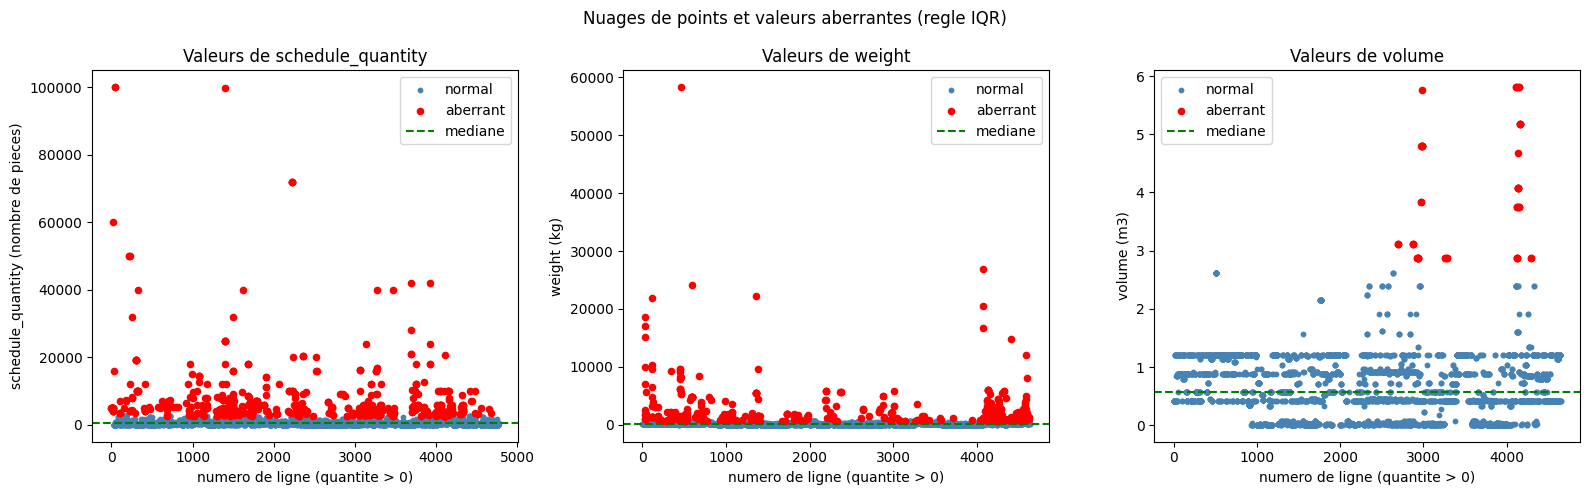

In [28]:
unites = {"schedule_quantity": "nombre de pieces", "weight": "kg", "volume": "m3"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, COLS_NUM):
    serie = base_ab[col].dropna()
    x = np.arange(len(serie))
    basse, haute = bornes_iqr(serie)
    est_aberrant = (serie.values < basse) | (serie.values > haute)

    ax.scatter(x[~est_aberrant], serie.values[~est_aberrant], s=10, color="steelblue", label="normal")
    ax.scatter(x[est_aberrant], serie.values[est_aberrant], s=20, color="red", label="aberrant")
    ax.axhline(serie.median(), color="green", linestyle="--", label="mediane")
    ax.set_title("Valeurs de " + col)
    ax.set_xlabel("numero de ligne (quantite > 0)")
    ax.set_ylabel(col + " (" + unites[col] + ")")
    ax.legend()

fig.suptitle("Nuages de points et valeurs aberrantes (regle IQR)")
plt.tight_layout()
plt.show()

Pour chaque colonne : les 10 lignes les plus éloignées de la médiane :

In [29]:
for col in COLS_NUM:
    mediane = base_ab[col].median()
    ecart = (base_ab[col] - mediane).abs()
    top = base_ab.assign(ecart_mediane=ecart.round(2)).sort_values("ecart_mediane", ascending=False)
    print("Colonne", col, "- mediane =", mediane)
    display(top.head(10)[["date", "supplier_id", "material", "plant", col, "ecart_mediane"]])

Colonne schedule_quantity - mediane = 400.0


,date,supplier_id,material,plant,schedule_quantity,ecart_mediane
58,2026-11-16,SUP_00091,MAT_001065,PLT_004,100000.0,99600.0
59,2027-01-01,SUP_00091,MAT_001065,PLT_004,100000.0,99600.0
1785,2027-01-01,SUP_00055,MAT_000671,PLT_001,99840.0,99440.0
2685,2026-12-16,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2682,2026-11-19,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2686,2027-01-01,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2683,2026-12-02,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
26,2027-01-01,SUP_00091,MAT_000110,PLT_004,60000.0,59600.0
280,2027-01-01,SUP_00061,MAT_000105,PLT_004,50000.0,49600.0
279,2026-11-16,SUP_00061,MAT_000105,PLT_004,50000.0,49600.0


Colonne weight - mediane = 146.4


,date,supplier_id,material,plant,weight,ecart_mediane
610,2027-01-01,SUP_00117,MAT_000700,PLT_004,58267.30,58120.90
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,26905.20,26758.80
773,2027-01-01,SUP_00117,MAT_000655,PLT_004,24099.86,23953.46
1741,2027-01-01,SUP_00024,MAT_000159,PLT_001,22212.40,22066.00
147,2026-11-11,SUP_00046,MAT_000486,PLT_004,21826.80,21680.40
5014,2026-12-01,SUP_00074,MAT_001164,PLT_003,20499.20,20352.80
39,2026-12-02,SUP_00046,MAT_000194,PLT_004,18536.20,18389.80
36,2026-11-11,SUP_00046,MAT_000194,PLT_004,17012.60,16866.20
5013,2026-11-17,SUP_00074,MAT_001164,PLT_003,16655.60,16509.20
38,2026-11-25,SUP_00046,MAT_000194,PLT_004,15235.20,15088.80


Colonne volume - mediane = 0.57


,date,supplier_id,material,plant,volume,ecart_mediane
5099,2026-11-27,SUP_00037,MAT_000153,PLT_002,5.808,5.24
5061,2026-11-12,SUP_00037,MAT_000583,PLT_002,5.808,5.24
5098,2026-11-26,SUP_00037,MAT_000153,PLT_002,5.808,5.24
5066,2026-11-20,SUP_00037,MAT_001110,PLT_002,5.808,5.24
5067,2026-11-27,SUP_00037,MAT_001110,PLT_002,5.808,5.24
3570,2027-01-01,SUP_00005,MAT_000326,PLT_001,5.760,5.19
5107,2026-11-27,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5104,2026-11-12,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5105,2026-11-20,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5106,2026-11-26,SUP_00037,MAT_000458,PLT_002,5.184,4.61


**Constat :** la règle IQR compte 1 183 valeurs « hors norme ». Ce ne sont pas des erreurs mais de vrais gros lots (jusqu'à 100 000 pièces, 58 tonnes) : on les garde. Sans le 1ᵉʳ janvier il en reste 1 124 — ce jour apporte surtout des lignes très lourdes.

### 2.8 Plausibilité métier

On confronte les données au bon sens du projet : une ligne ne devrait pas
dépasser la capacité d'un camion, il ne devrait pas y avoir de besoin le
week-end, et la charge devrait se répartir normalement sur la semaine.

Lignes qui dépassent à elles seules la capacité d'un camion :

In [30]:
depasse_poids = schedule[schedule["weight"] > CAP_POIDS]
depasse_volume = schedule[schedule["volume"] > CAP_VOLUME]
print("Lignes dont le poids depasse", CAP_POIDS, "kg :", len(depasse_poids))
print("Lignes dont le volume depasse", CAP_VOLUME, "m3 :", len(depasse_volume))
if len(depasse_poids) > 0:
    display(depasse_poids[["date", "supplier_id", "material", "plant",
                           "schedule_quantity", "weight", "volume"]])

Lignes dont le poids depasse 24500.0 kg : 2
Lignes dont le volume depasse 110.4 m3 : 0


,date,supplier_id,material,plant,schedule_quantity,weight,volume
610,2027-01-01,SUP_00117,MAT_000700,PLT_004,5320.0,58267.3,1.1424
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,5670.0,26905.2,0.8400


Besoins tombant un samedi ou un dimanche :

In [31]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
jour_semaine = d_besoin.dt.dayofweek          # 0 = lundi ... 6 = dimanche
week_end = schedule[jour_semaine >= 5]
week_end_reels = week_end[week_end["schedule_quantity"] > 0]
print("Lignes datees d'un samedi/dimanche :", len(week_end))
print("  dont avec une quantite > 0       :", len(week_end_reels))

Lignes datees d'un samedi/dimanche : 0
  dont avec une quantite > 0       : 0


Répartition des lignes et du poids par jour de la semaine :

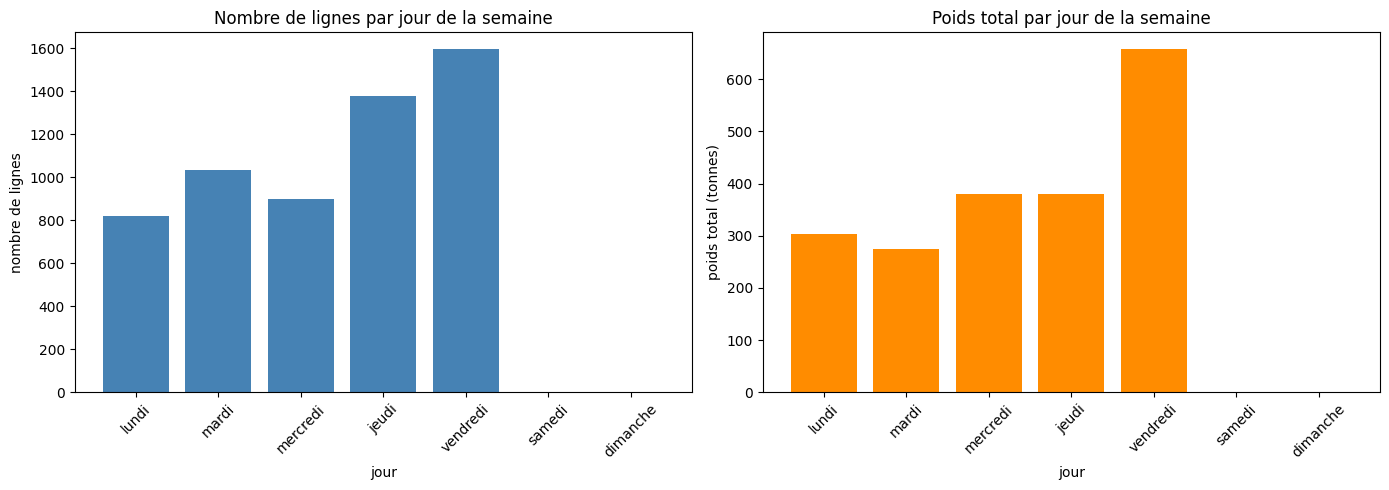

In [32]:
noms_jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
travail = schedule.assign(jour=jour_semaine)
nb_lignes_jour = travail.groupby("jour").size().reindex(range(7), fill_value=0)
poids_jour = travail.groupby("jour")["weight"].sum().reindex(range(7), fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(noms_jours, nb_lignes_jour.values, color="steelblue")
ax1.set_title("Nombre de lignes par jour de la semaine")
ax1.set_xlabel("jour"); ax1.set_ylabel("nombre de lignes")
ax1.tick_params(axis="x", rotation=45)

ax2.bar(noms_jours, poids_jour.values / 1000, color="darkorange")
ax2.set_title("Poids total par jour de la semaine")
ax2.set_xlabel("jour"); ax2.set_ylabel("poids total (tonnes)")
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Constat :** 2 lignes pèsent plus qu'un camion entier (24,5 t) : à répartir sur plusieurs camions. Aucun besoin le week-end.

### 2.9 Couverture temporelle

On vérifie que la période couverte est continue : semaines absentes, semaines
anormalement chargées ou vides, et nombre de versions du planning.

Période couverte :

In [33]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
print("Premiere date :", d_besoin.min().date())
print("Derniere date :", d_besoin.max().date())
print("Duree couverte :", (d_besoin.max() - d_besoin.min()).days, "jours")

# Sans le 1er janvier (point de rejet)
d_sans = pd.to_datetime(schedule_sans_jan["date"], errors="coerce")
print()
print("Sans le 1er janvier -> derniere vraie date :", d_sans.max().date())

Premiere date : 2026-11-09
Derniere date : 2027-01-01
Duree couverte : 53 jours

Sans le 1er janvier -> derniere vraie date : 2026-12-30


Semaines présentes et semaines manquantes entre la première et la dernière date (repère : le lundi de la semaine). On compte aussi le nombre de lignes par semaine pour repérer les semaines **quasi vides** — typiquement l'**arrêt de Noël**, qu'une simple liste de semaines « présentes » ne voit pas.

In [34]:
semaine = d_besoin.dt.to_period("W")
semaines_presentes = pd.PeriodIndex(semaine.dropna().unique()).sort_values()
semaines_attendues = pd.period_range(semaines_presentes.min(), semaines_presentes.max(), freq="W")
semaines_manquantes = semaines_attendues.difference(semaines_presentes)

print("Nombre de semaines presentes :", len(semaines_presentes))
print("Nombre de semaines attendues :", len(semaines_attendues))
print("Semaines manquantes          :", len(semaines_manquantes))
for s in semaines_manquantes:
    print("  manquante :", s.start_time.date(), "->", s.end_time.date())

# Une semaine peut etre "presente" mais quasi vide (arret de Noel) : on compte les lignes.
lignes_par_sem = semaine.value_counts().sort_index()
seuil = 0.15 * lignes_par_sem.median()   # moins de 15 % d'une semaine normale = quasi vide
print()
print("Lignes par semaine (seuil quasi-vide =", round(seuil), ") :")
for p, nb_l in lignes_par_sem.items():
    marque = "  <-- QUASI VIDE (arret de Noel ?)" if nb_l < seuil else ""
    print("  ", p.start_time.date(), "->", p.end_time.date(), ":", int(nb_l), "lignes", marque)

Nombre de semaines presentes : 8
Nombre de semaines attendues : 8
Semaines manquantes          : 0

Lignes par semaine (seuil quasi-vide = 113 ) :
   2026-11-09 -> 2026-11-15 : 828 lignes 
   2026-11-16 -> 2026-11-22 : 922 lignes 
   2026-11-23 -> 2026-11-29 : 1446 lignes 
   2026-11-30 -> 2026-12-06 : 912 lignes 
   2026-12-07 -> 2026-12-13 : 673 lignes 
   2026-12-14 -> 2026-12-20 : 521 lignes 
   2026-12-21 -> 2026-12-27 : 3 lignes   <-- QUASI VIDE (arret de Noel ?)
   2026-12-28 -> 2027-01-03 : 423 lignes 


Nombre de lignes et poids total par semaine :

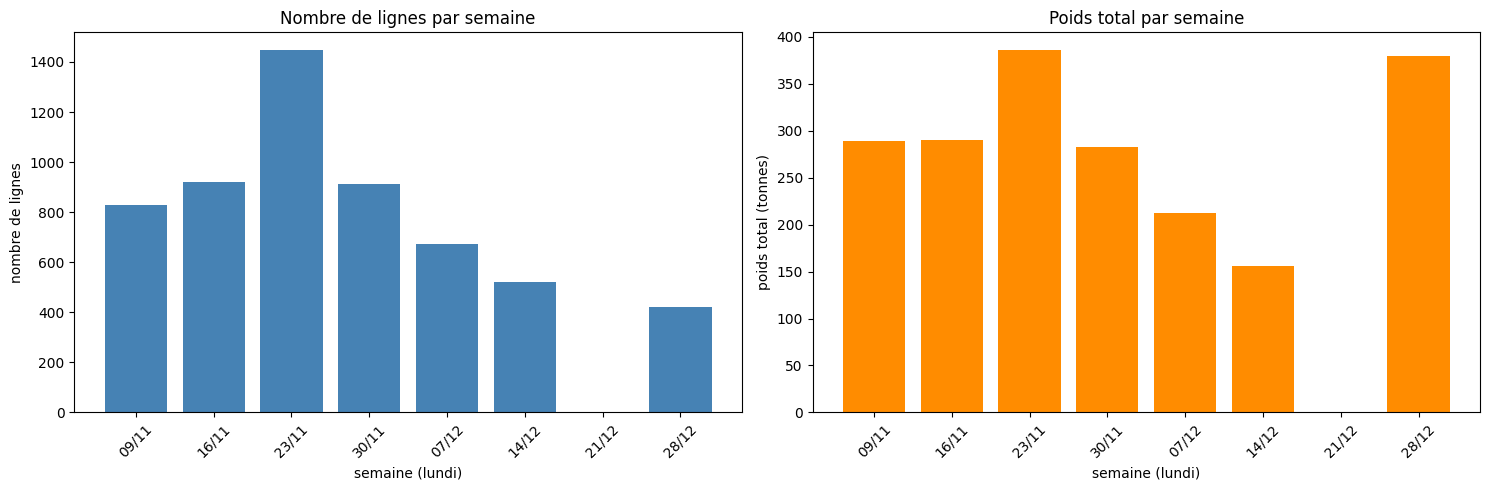

In [35]:
travail = schedule.assign(semaine=semaine.dt.start_time)
par_semaine = travail.groupby("semaine").agg(
    nb_lignes=("date", "size"),
    poids_total=("weight", "sum"),
).reset_index()
etiquettes = par_semaine["semaine"].dt.strftime("%d/%m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.bar(etiquettes, par_semaine["nb_lignes"], color="steelblue")
ax1.set_title("Nombre de lignes par semaine")
ax1.set_xlabel("semaine (lundi)"); ax1.set_ylabel("nombre de lignes")
ax1.tick_params(axis="x", rotation=45)

ax2.bar(etiquettes, par_semaine["poids_total"] / 1000, color="darkorange")
ax2.set_title("Poids total par semaine")
ax2.set_xlabel("semaine (lundi)"); ax2.set_ylabel("poids total (tonnes)")
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Nombre de versions du planning :

In [36]:
print("Nombre de versions (version_date) :", schedule["version_date"].nunique())
print("Valeur(s) :", list(schedule["version_date"].unique()))

Nombre de versions (version_date) : 1
Valeur(s) : ['2026-11-08']


**Constat :** le planning va du 9 novembre 2026 au 1ᵉʳ janvier 2027. Aucune semaine n'est totalement absente, **mais** la semaine de **Noël (21–27 décembre)** est quasi vide (3 lignes) : l'usine s'arrête pour les fêtes. Et la dernière semaine (28/12) est remplie presque uniquement par le 1ᵉʳ janvier « fourre-tout ». La vraie dernière date de travail est donc le **30 décembre**. Il n'y a qu'une seule version du planning.

### 2.10 Analyse par usine

C'est le cœur du projet : combien de camions faut-il par usine et par
semaine ? On compare le minimum théorique (tout le poids de l'usine regroupé)
au calcul réaliste (un camion ne mélange pas deux fournisseurs).

Nombre de fournisseurs par usine et nombre de couples fournisseur x usine :

In [37]:
fourn_par_usine = schedule.groupby("plant")["supplier_id"].nunique()
print("Fournisseurs par usine :")
display(fourn_par_usine.to_frame("nb_fournisseurs"))
nb_couples = schedule[["supplier_id", "plant"]].drop_duplicates().shape[0]
print("Nombre de couples fournisseur x usine :", nb_couples)

Fournisseurs par usine :


,nb_fournisseurs
plant,
PLT_001,52
PLT_002,64
PLT_003,26
PLT_004,43


Nombre de couples fournisseur x usine : 185


Base de travail : copie avec la semaine, poids/volume vides comptés comme 0 pour pouvoir additionner.

In [38]:
base10 = schedule.copy()
base10["semaine"] = pd.to_datetime(base10["date"], errors="coerce").dt.to_period("W").dt.start_time
base10["weight"] = base10["weight"].fillna(0.0)
base10["volume"] = base10["volume"].fillna(0.0)
usines = sorted(base10["plant"].unique())
print("Usines :", usines)

Usines : ['PLT_001', 'PLT_002', 'PLT_003', 'PLT_004']


Un graphique par usine : poids (tonnes, axe gauche) et volume (m³, axe droit) par semaine, en barres côte à côte.

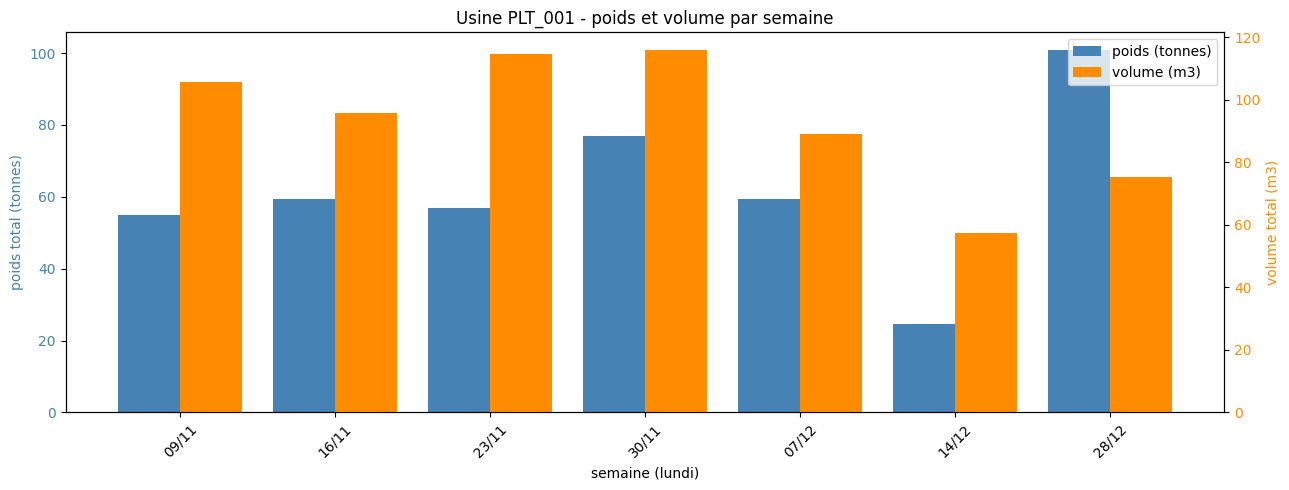

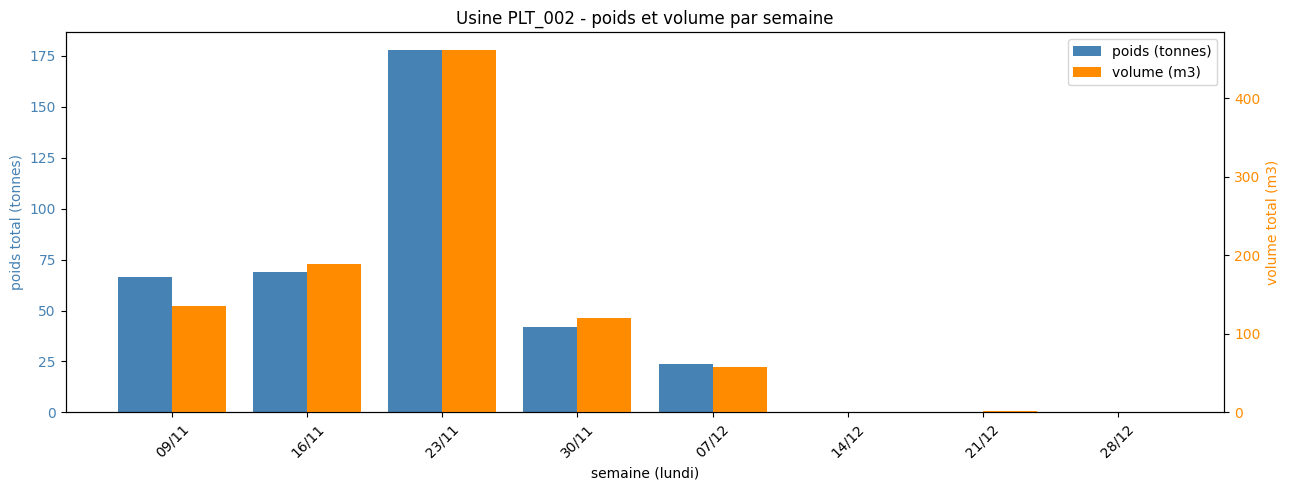

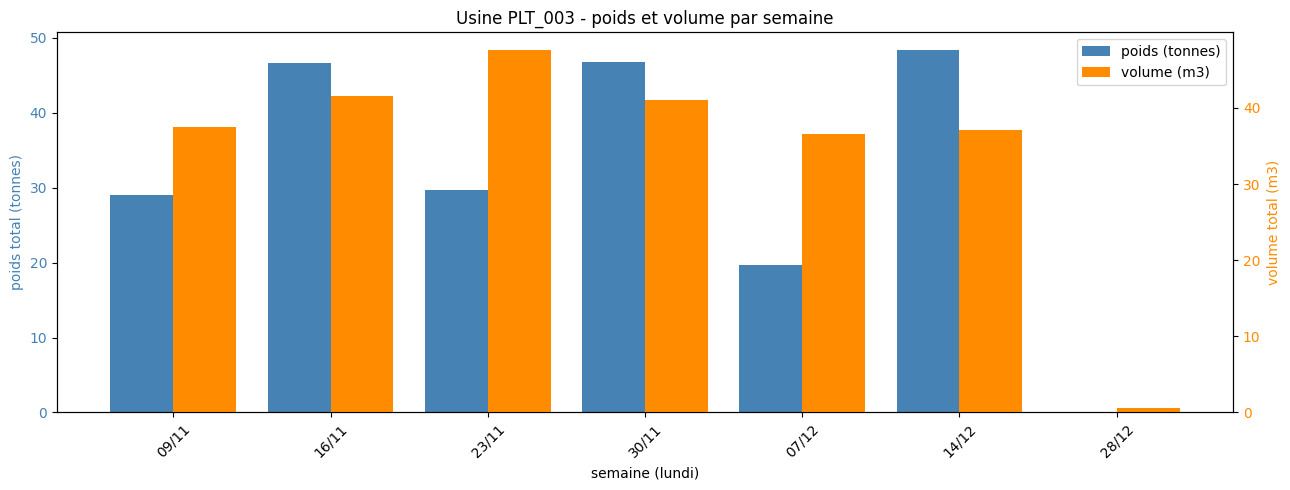

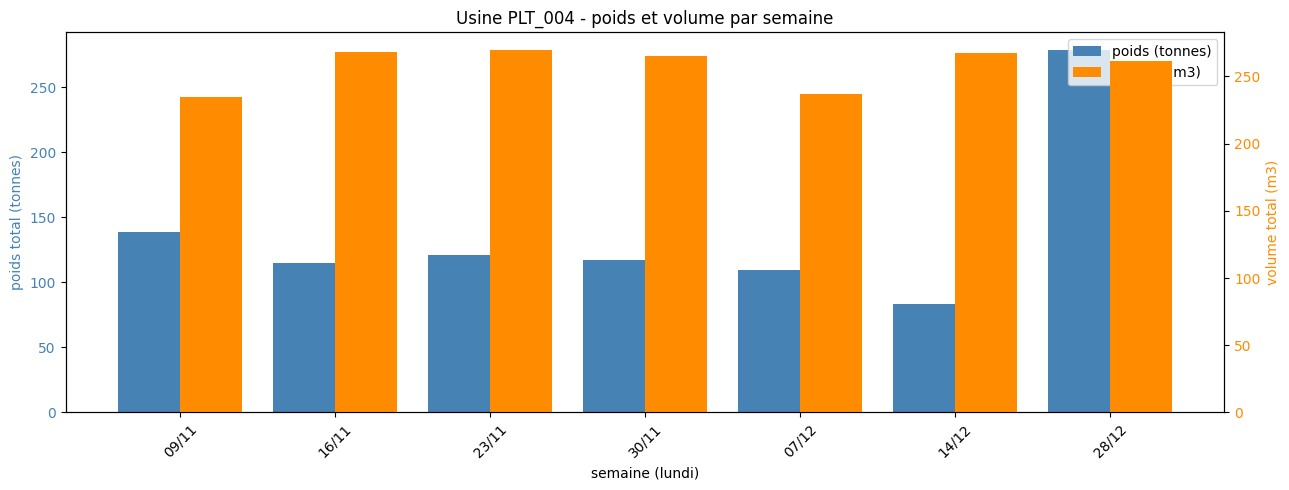

In [39]:
for usine in usines:
    sous = base10[base10["plant"] == usine]
    agg = sous.groupby("semaine").agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
    etiquettes = agg["semaine"].dt.strftime("%d/%m")
    x = np.arange(len(agg))
    largeur = 0.4

    fig, ax_poids = plt.subplots(figsize=(13, 5))
    ax_vol = ax_poids.twinx()
    ax_poids.bar(x - largeur / 2, agg["poids"] / 1000, width=largeur, color="steelblue", label="poids (tonnes)")
    ax_vol.bar(x + largeur / 2, agg["volume"], width=largeur, color="darkorange", label="volume (m3)")

    ax_poids.set_title("Usine " + usine + " - poids et volume par semaine")
    ax_poids.set_xlabel("semaine (lundi)")
    ax_poids.set_ylabel("poids total (tonnes)", color="steelblue")
    ax_vol.set_ylabel("volume total (m3)", color="darkorange")
    ax_poids.set_xticks(x); ax_poids.set_xticklabels(etiquettes, rotation=45)
    ax_poids.tick_params(axis="y", labelcolor="steelblue")
    ax_vol.tick_params(axis="y", labelcolor="darkorange")
    b1, l1 = ax_poids.get_legend_handles_labels()
    b2, l2 = ax_vol.get_legend_handles_labels()
    ax_poids.legend(b1 + b2, l1 + l2, loc="upper right")
    plt.tight_layout()
    plt.show()

Nombre de camions nécessaires par usine et par semaine.
Règle : camions = max(arrondi supérieur(poids / 24 500), arrondi supérieur(volume / 110,4)).
Version **a** = minimum théorique (tout regroupé) ; version **b** = réaliste
(par couple fournisseur x usine, puis somme).

In [40]:
def nb_camions(poids, volume):
    return max(int(np.ceil(poids / CAP_POIDS)), int(np.ceil(volume / CAP_VOLUME)))

# Version a : minimum theorique
theorique = (base10.groupby(["plant", "semaine"])
             .agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index())
theorique["camions_a"] = theorique.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1)

# Version b : realiste, par couple fournisseur x usine
par_couple = (base10.groupby(["plant", "semaine", "supplier_id"])
              .agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index())
par_couple["camions"] = par_couple.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1)
par_couple["camions_poids"] = np.ceil(par_couple["poids"] / CAP_POIDS).astype(int)
par_couple["camions_volume"] = np.ceil(par_couple["volume"] / CAP_VOLUME).astype(int)
par_couple["limite"] = np.where(par_couple["camions_poids"] >= par_couple["camions_volume"], "poids", "volume")

realiste = (par_couple.groupby(["plant", "semaine"])["camions"].sum()
            .reset_index().rename(columns={"camions": "camions_b"}))

comparaison = theorique.merge(realiste, on=["plant", "semaine"])
comparaison.head(12)

,plant,semaine,poids,volume,camions_a,camions_b
0,PLT_001,2026-11-09,55068.23,105.790820,3,43
1,PLT_001,2026-11-16,59337.29,95.819895,3,38
2,PLT_001,2026-11-23,56981.46,114.856243,3,40
3,PLT_001,2026-11-30,76811.16,115.849286,4,45
4,PLT_001,2026-12-07,59274.66,89.260050,3,35
5,PLT_001,2026-12-14,24648.86,57.285000,2,26
6,PLT_001,2026-12-28,100737.25,75.231360,5,32
7,PLT_002,2026-11-09,66242.46,135.310076,3,37
8,PLT_002,2026-11-16,68838.62,188.388386,3,45
9,PLT_002,2026-11-23,177551.14,460.699685,8,56


Quelle limite (poids ou volume) déclenche le plus souvent un camion ?

In [41]:
actifs = par_couple[par_couple["camions"] > 0]
display(actifs["limite"].value_counts().to_frame("nb_couples"))
part_volume = (actifs["limite"] == "volume").mean()
print("Le volume est", "souvent" if part_volume > 0.5 else "rarement", "la contrainte la plus serrante.")

,nb_couples
limite,
poids,775
volume,31


Le volume est rarement la contrainte la plus serrante.


Diagramme en barres groupées : semaines en abscisse, une couleur par usine (version réaliste b).

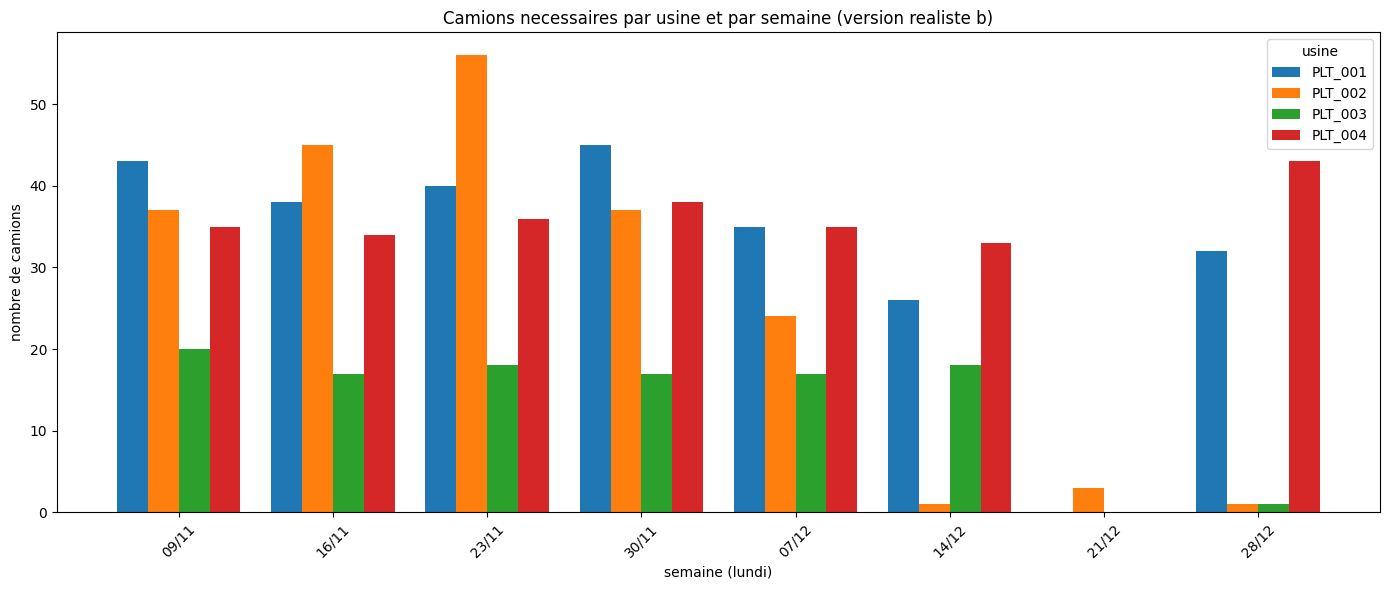

In [42]:
pivot = realiste.pivot(index="semaine", columns="plant", values="camions_b").fillna(0)
etiquettes = pivot.index.strftime("%d/%m")
x = np.arange(len(pivot))
n_usines = pivot.shape[1]
largeur = 0.8 / n_usines

fig, ax = plt.subplots(figsize=(14, 6))
for i, usine in enumerate(pivot.columns):
    ax.bar(x + (i - (n_usines - 1) / 2) * largeur, pivot[usine].values, width=largeur, label=usine)
ax.set_title("Camions necessaires par usine et par semaine (version realiste b)")
ax.set_xlabel("semaine (lundi)"); ax.set_ylabel("nombre de camions")
ax.set_xticks(x); ax.set_xticklabels(etiquettes, rotation=45)
ax.legend(title="usine")
plt.tight_layout()
plt.show()

Comparaison globale théorique (a) vs réaliste (b) :

In [43]:
total_a = int(comparaison["camions_a"].sum())
total_b = int(comparaison["camions_b"].sum())
print("Total camions - minimum theorique (a)   :", total_a)
print("Total camions - realiste par couple (b) :", total_b)
print("Surcout du au non-melange des fournisseurs :", total_b - total_a, "camions")

# Meme calcul sans le 1er janvier (point de rejet)
base10_sans = base10[base10["date"] != JOUR_REJET]
th_s = base10_sans.groupby(["plant", "semaine"]).agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
a_s = int(th_s.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1).sum())
pc_s = base10_sans.groupby(["plant", "semaine", "supplier_id"]).agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
b_s = int(pc_s.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1).sum())
print()
print("Sans le 1er janvier :")
print("  minimum theorique (a)   :", a_s)
print("  realiste par couple (b) :", b_s)
print("  -> le 1er janvier pese", total_b - b_s, "camions sur", total_b)

Total camions - minimum theorique (a)   : 97
Total camions - realiste par couple (b) : 825
Surcout du au non-melange des fournisseurs : 728 camions

Sans le 1er janvier :
  minimum theorique (a)   : 79
  realiste par couple (b) : 749
  -> le 1er janvier pese 76 camions sur 825


**Constat :** en regroupant tout, 97 camions suffiraient ; en réalité (sans mélanger les fournisseurs) il en faut **825**, soit +728. C'est le gros levier d'économie. C'est presque toujours le **poids** qui remplit le camion, pas le volume. À lui seul, le 1ᵉʳ janvier pèse 76 camions : sans lui on tombe à 749.

### 2.11 Bilan des anomalies

Tableau de synthèse reprenant les anomalies trouvées dans les sections 2.3 à
2.10. Les compteurs sont calculés ici ; les colonnes `impact` et `décision`
sont à compléter après lecture des résultats.

In [44]:
n = len(schedule)
anomalies = [
    {"anomalie": "Poids manquant (vide)", "nb_lignes": int(schedule["weight"].isna().sum()),
     "impact_sur_le_projet": "fausse le poids par camion", "decision_proposee": "combler (poids median de la piece) ou signaler"},
    {"anomalie": "Volume manquant (vide)", "nb_lignes": int(schedule["volume"].isna().sum()),
     "impact_sur_le_projet": "fausse le remplissage en volume", "decision_proposee": "combler ou signaler"},
    {"anomalie": "Quantite = 0", "nb_lignes": int((schedule["schedule_quantity"] == 0).sum()),
     "impact_sur_le_projet": "aucun : jour sans livraison", "decision_proposee": "garder tel quel"},
    {"anomalie": "Poids = 0", "nb_lignes": int((schedule["weight"] == 0).sum()),
     "impact_sur_le_projet": "aucun : jour sans livraison", "decision_proposee": "garder tel quel"},
    {"anomalie": "Doublons sur la cle", "nb_lignes": int(schedule.duplicated(subset=cle, keep=False).sum()),
     "impact_sur_le_projet": "aucun", "decision_proposee": "rien a faire"},
    {"anomalie": "Identifiants non conformes", "nb_lignes": int(conformite_ids["nb_non_conformes"].sum()),
     "impact_sur_le_projet": "aucun", "decision_proposee": "rien a faire"},
    {"anomalie": "Poids > capacite camion (24 500 kg)", "nb_lignes": int((schedule["weight"] > CAP_POIDS).sum()),
     "impact_sur_le_projet": "impossible a charger sur un seul camion", "decision_proposee": "repartir sur plusieurs camions"},
    {"anomalie": "Volume > capacite camion (110,4 m3)", "nb_lignes": int((schedule["volume"] > CAP_VOLUME).sum()),
     "impact_sur_le_projet": "aucun (0 ligne)", "decision_proposee": "rien a faire"},
    {"anomalie": "Besoin le week-end (quantite > 0)", "nb_lignes": int(len(week_end_reels)),
     "impact_sur_le_projet": "aucun (0 ligne)", "decision_proposee": "rien a faire"},
    {"anomalie": "Besoin au 2027-01-01 (point de rejet)", "nb_lignes": int((schedule["date"] == "2027-01-01").sum()),
     "impact_sur_le_projet": "gonfle la derniere semaine (quantites et poids)", "decision_proposee": "traiter a part, ne pas melanger aux vrais jours"},
]
bilan = pd.DataFrame(anomalies)
bilan["pct"] = (bilan["nb_lignes"] / n * 100).round(2)
bilan[["anomalie", "nb_lignes", "pct", "impact_sur_le_projet", "decision_proposee"]]

,anomalie,nb_lignes,pct,impact_sur_le_projet,decision_proposee
0,Poids manquant (vide),169,2.95,fausse le poids par camion,combler (poids median de la piece) ou signaler
1,Volume manquant (vide),147,2.57,fausse le remplissage en volume,combler ou signaler
2,Quantite = 0,959,16.74,aucun : jour sans livraison,garder tel quel
3,Poids = 0,929,16.22,aucun : jour sans livraison,garder tel quel
4,Doublons sur la cle,0,0.00,aucun,rien a faire
5,Identifiants non conformes,0,0.00,aucun,rien a faire
6,Poids > capacite camion (24 500 kg),2,0.03,impossible a charger sur un seul camion,repartir sur plusieurs camions
7,"Volume > capacite camion (110,4 m3)",0,0.00,aucun (0 ligne),rien a faire
8,Besoin le week-end (quantite > 0),0,0.00,aucun (0 ligne),rien a faire
9,Besoin au 2027-01-01 (point de rejet),420,7.33,gonfle la derniere semaine (quantites et poids),"traiter a part, ne pas melanger aux vrais jours"


**Constat :** les données sont saines et utilisables. Les seuls vrais points à traiter : les poids/volumes manquants (≈ 3 %), les 2 lignes trop lourdes pour un camion, et le **1ᵉʳ janvier 2027** qui concentre à lui seul 7 % des lignes, 16 % des quantités et 19 % du poids. Décisions : combler ou signaler les vides, scinder les 2 lignes lourdes, et traiter le 1ᵉʳ janvier à part sans le mélanger aux vrais jours.